# 03 — Feature Engineering (split-first)

**Règle clé :** le split est effectué *avant* tout feature engineering pour éviter le data leakage.

Pipeline :
1. Charger `interim/combined_labeled.csv`
2. Split Train / Val / Test (70/15/15) — avant toute transformation
3. SMILES → Morgan Fingerprints (2048 bits, déterministe)
4. SMILES → Descripteurs RDKit (30 descripteurs)
5. Imputation NaN — `SimpleImputer` fitté sur train uniquement
6. VarianceThreshold — fitté sur train uniquement
7. StandardScaler — fitté sur train uniquement
8. Combinaison Morgan + Descripteurs scalés + sauvegarde des splits

In [24]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
import joblib

INTERIM_DIR   = Path('../data/interim')
PROCESSED_DIR = Path('../data/processed')
FIGURES_DIR   = Path('../reports/figures')

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Chargement des données

In [25]:
df = pd.read_csv(INTERIM_DIR / 'combined_labeled.csv')
print(f'Shape : {df.shape}')
print(f'Colonnes : {df.columns.tolist()}')
print(f'\nDistribution is_toxic :')
print(df['is_toxic'].value_counts())
df.head(3)

Shape : (8799, 3)
Colonnes : ['smiles', 'is_toxic', 'source']

Distribution is_toxic :
is_toxic
0    5863
1    2936
Name: count, dtype: int64


,smiles,is_toxic,source
0,Oc1ccc(Cc2ccc(O)cc2)cc1,1,tox21
1,CC[S+](C)CC.O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)...,1,tox21
2,CCN(CC)CC(=O)Nc1c(C)cccc1C,1,clintox


## 2. Train / Val / Test Split — avant le feature engineering

In [26]:
df_train, df_test = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE, stratify=df['is_toxic']
)

df_train = df_train.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

y_train = df_train['is_toxic'].values
y_test  = df_test['is_toxic'].values

print(f'Train : {len(df_train)}  | pos={y_train.sum()} ({y_train.mean():.1%})')
print(f'Test  : {len(df_test)}  | pos={y_test.sum()} ({y_test.mean():.1%})')

Train : 7039  | pos=2349 (33.4%)
Test  : 1760  | pos=587 (33.4%)


## 3. Morgan Fingerprints (2048 bits, radius=2)

In [27]:
def smiles_to_morgan(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.zeros(n_bits, dtype=np.int8)
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=radius, nBits=n_bits)
    return np.array(fp, dtype=np.int8)

morgan_cols = [f'morgan_{i}' for i in range(2048)]

print('Calcul des Morgan Fingerprints...')
X_morgan_train = np.vstack(df_train['smiles'].apply(smiles_to_morgan).values)
X_morgan_test  = np.vstack(df_test['smiles'].apply(smiles_to_morgan).values)

print(f'Morgan train : {X_morgan_train.shape}')
print(f'Morgan test  : {X_morgan_test.shape}')
print(f'Bits actifs moyen (train) : {X_morgan_train.sum(axis=1).mean():.1f} / 2048')

Calcul des Morgan Fingerprints...
Morgan train : (7039, 2048)
Morgan test  : (1760, 2048)
Bits actifs moyen (train) : 31.7 / 2048


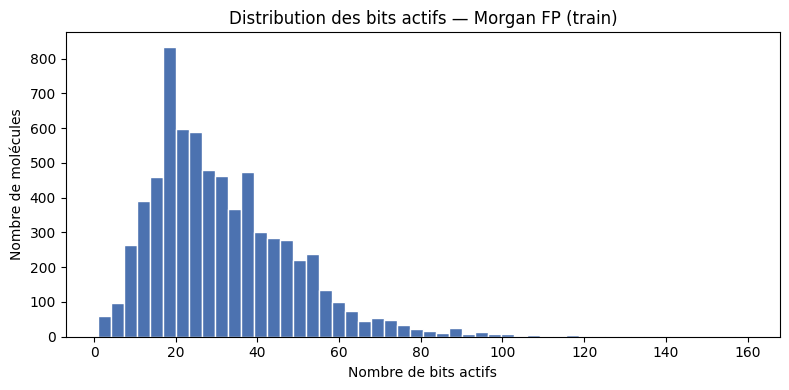

In [28]:
active_bits = X_morgan_train.sum(axis=1)
plt.figure(figsize=(8, 4))
plt.hist(active_bits, bins=50, color='#4C72B0', edgecolor='white')
plt.xlabel('Nombre de bits actifs')
plt.ylabel('Nombre de molécules')
plt.title('Distribution des bits actifs — Morgan FP (train)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'morgan_active_bits.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Descripteurs RDKit

Calcul des descripteurs RDKit...
Descripteurs train : (7039, 30)
NaN train          : 0


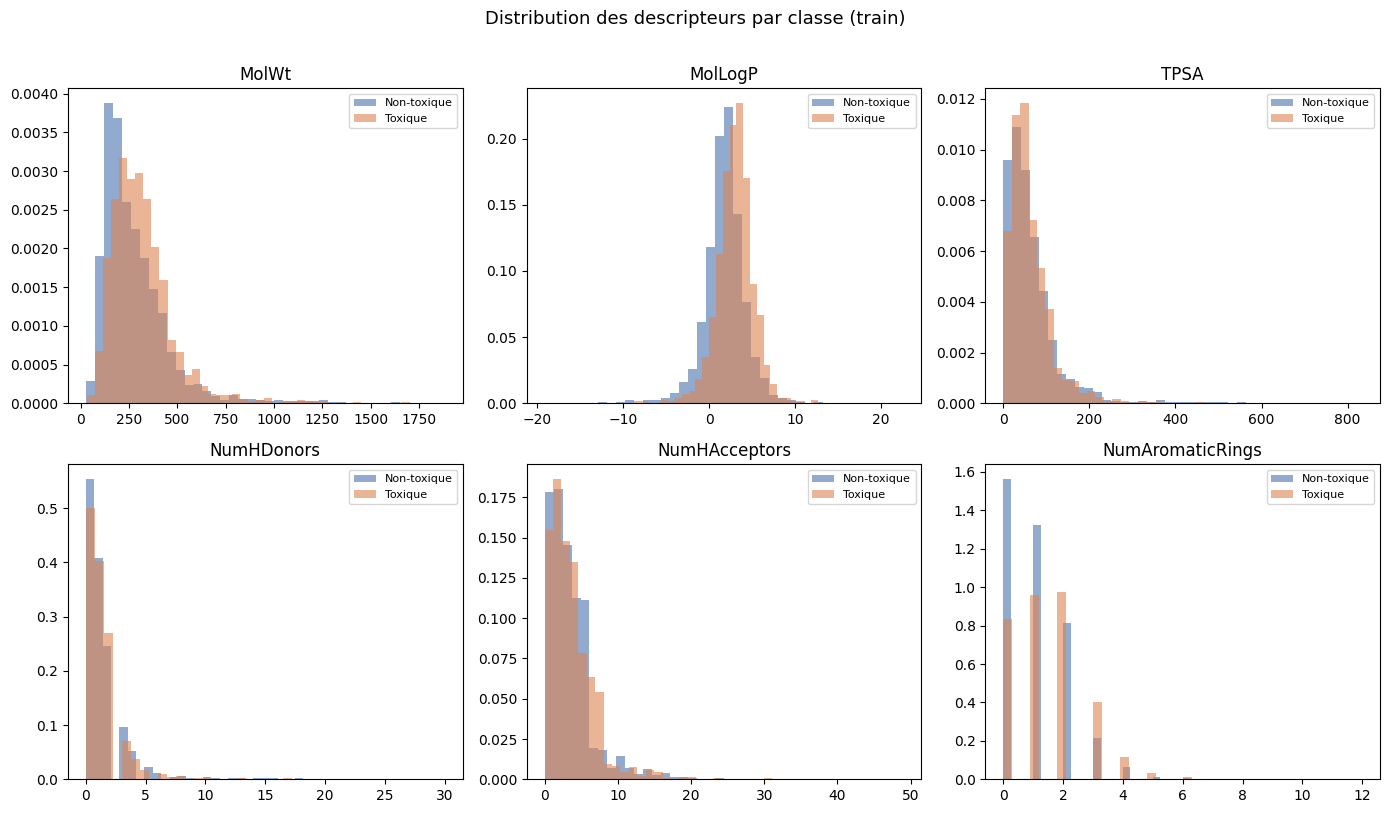

In [29]:
DESCRIPTOR_LIST = [
    ('MolWt',               Descriptors.MolWt),
    ('MolLogP',             Descriptors.MolLogP),
    ('TPSA',                Descriptors.TPSA),
    ('NumHDonors',          Descriptors.NumHDonors),
    ('NumHAcceptors',       Descriptors.NumHAcceptors),
    ('NumRotatableBonds',   Descriptors.NumRotatableBonds),
    ('NumAromaticRings',    Descriptors.NumAromaticRings),
    ('NumAliphaticRings',   Descriptors.NumAliphaticRings),
    ('RingCount',           Descriptors.RingCount),
    ('FractionCSP3',        Descriptors.FractionCSP3),
    ('HeavyAtomCount',      Descriptors.HeavyAtomCount),
    ('NumHeteroatoms',      Descriptors.NumHeteroatoms),
    ('MolMR',               Descriptors.MolMR),
    ('BalabanJ',            Descriptors.BalabanJ),
    ('BertzCT',             Descriptors.BertzCT),
    ('Ipc',                 Descriptors.Ipc),
    ('Kappa1',              Descriptors.Kappa1),
    ('Kappa2',              Descriptors.Kappa2),
    ('Kappa3',              Descriptors.Kappa3),
    ('MaxAbsEStateIndex',   Descriptors.MaxAbsEStateIndex),
    ('MinAbsEStateIndex',   Descriptors.MinAbsEStateIndex),
    ('MaxEStateIndex',      Descriptors.MaxEStateIndex),
    ('MinEStateIndex',      Descriptors.MinEStateIndex),
    ('Chi0',                Descriptors.Chi0),
    ('Chi1',                Descriptors.Chi1),
    ('Chi2n',               Descriptors.Chi2n),
    ('Chi3n',               Descriptors.Chi3n),
    ('Chi4n',               Descriptors.Chi4n),
    ('LabuteASA',           Descriptors.LabuteASA),
    ('PEOE_VSA1',           Descriptors.PEOE_VSA1),
]
desc_names = [name for name, _ in DESCRIPTOR_LIST]

def compute_descriptors(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return [np.nan] * len(DESCRIPTOR_LIST)
    values = []
    for _, fn in DESCRIPTOR_LIST:
        try:
            values.append(fn(mol))
        except Exception:
            values.append(np.nan)
    return values

print('Calcul des descripteurs RDKit...')
X_desc_train_raw = np.array(df_train['smiles'].apply(compute_descriptors).tolist())
X_desc_test_raw  = np.array(df_test['smiles'].apply(compute_descriptors).tolist())

print(f'Descripteurs train : {X_desc_train_raw.shape}')
print(f'NaN train          : {np.isnan(X_desc_train_raw).sum()}')

# Visualisation des descripteurs clés par classe (train uniquement)
key_desc = ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumAromaticRings']
df_plot = pd.DataFrame(X_desc_train_raw, columns=desc_names)[key_desc].copy()
df_plot['is_toxic'] = y_train

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(key_desc):
    for label, color, name in [(0, '#4C72B0', 'Non-toxique'), (1, '#DD8452', 'Toxique')]:
        axes[i].hist(
            df_plot[df_plot['is_toxic'] == label][col].dropna(),
            bins=40, alpha=0.6, color=color, label=name, density=True
        )
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)
plt.suptitle('Distribution des descripteurs par classe (train)', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'descriptors_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [30]:
# SimpleImputer fitté sur train uniquement — la médiane de val/test ne doit jamais influencer
imputer = SimpleImputer(strategy='median')
X_desc_train_imp = imputer.fit_transform(X_desc_train_raw)
X_desc_test_imp  = imputer.transform(X_desc_test_raw)

print(f'NaN après imputation — train : {np.isnan(X_desc_train_imp).sum()}')
print(f'NaN après imputation — test  : {np.isnan(X_desc_test_imp).sum()}')

NaN après imputation — train : 0
NaN après imputation — test  : 0


## 5. VarianceThreshold sur les Morgan FP (fit sur train)

In [31]:
vt = VarianceThreshold(threshold=0.0)
X_morgan_train_vt = vt.fit_transform(X_morgan_train)
X_morgan_test_vt  = vt.transform(X_morgan_test)

morgan_cols_kept = [morgan_cols[i] for i in vt.get_support(indices=True)]

print(f'Morgan bits après VarianceThreshold : {X_morgan_train_vt.shape[1]} / 2048')
print(f'  (masque calculé sur train uniquement)')

Morgan bits après VarianceThreshold : 2048 / 2048
  (masque calculé sur train uniquement)


## 6. StandardScaler sur les descripteurs (fit sur train)

In [32]:
scaler = StandardScaler()
X_desc_train_scaled = scaler.fit_transform(X_desc_train_imp)
X_desc_test_scaled  = scaler.transform(X_desc_test_imp)

print('Stats descripteurs scalés (train) :')
print(f'  mean ≈ {X_desc_train_scaled.mean():.4f}  (doit être ≈ 0)')
print(f'  std  ≈ {X_desc_train_scaled.std():.4f}   (doit être ≈ 1)')
print('Stats descripteurs scalés (test) :')
print(f'  mean ≈ {X_desc_test_scaled.mean():.4f}')
print(f'  std  ≈ {X_desc_test_scaled.std():.4f}')

Stats descripteurs scalés (train) :
  mean ≈ -0.0000  (doit être ≈ 0)
  std  ≈ 1.0000   (doit être ≈ 1)
Stats descripteurs scalés (test) :
  mean ≈ -0.0078
  std  ≈ 0.9558


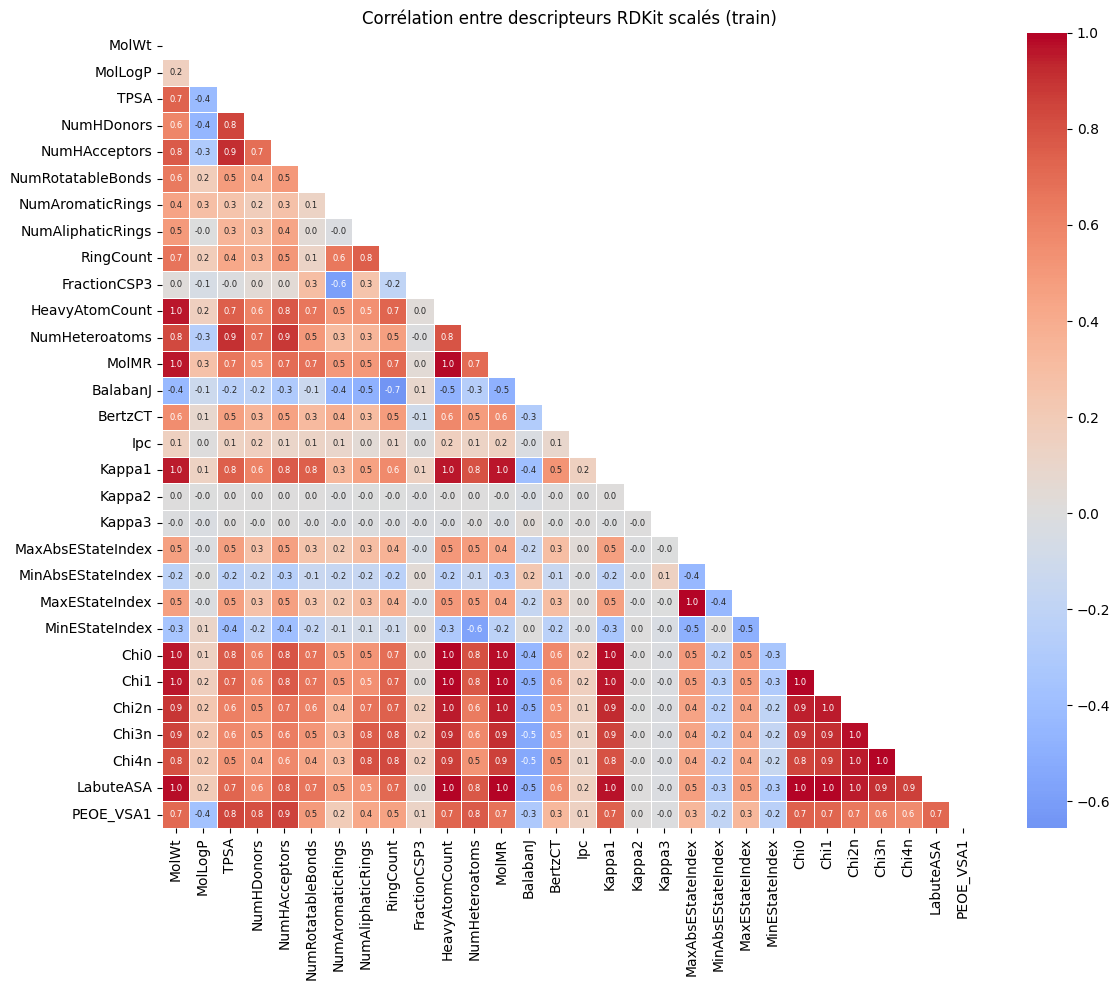

In [33]:
corr = pd.DataFrame(X_desc_train_scaled, columns=desc_names).corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.1f', cmap='coolwarm',
    center=0, linewidths=0.5, annot_kws={'size': 6}
)
plt.title('Corrélation entre descripteurs RDKit scalés (train)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'descriptors_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Combinaison & Sauvegarde

In [35]:
# Combinaison Morgan (après VT) + Descripteurs scalés
X_train = np.hstack([X_morgan_train_vt.astype(np.float32), X_desc_train_scaled.astype(np.float32)])
X_test  = np.hstack([X_morgan_test_vt.astype(np.float32),  X_desc_test_scaled.astype(np.float32)])

print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')

# Sauvegarde des splits (écrase les .npy du notebook 02)
np.save(PROCESSED_DIR / 'X_train.npy', X_train)
np.save(PROCESSED_DIR / 'y_train.npy', y_train)
np.save(PROCESSED_DIR / 'X_test.npy',  X_test)
np.save(PROCESSED_DIR / 'y_test.npy',  y_test)

# Transformeurs sérialisés (tous fittés sur train uniquement)
joblib.dump(imputer, PROCESSED_DIR / 'descriptor_imputer.pkl')
joblib.dump(scaler,  PROCESSED_DIR / 'descriptor_scaler.pkl')
joblib.dump(vt,      PROCESSED_DIR / 'variance_threshold.pkl')

# Noms des features
feature_names = morgan_cols_kept + desc_names
pd.Series(feature_names).to_csv(PROCESSED_DIR / 'feature_names.csv', index=False, header=['feature'])

print('\nFichiers sauvegardés :')
for f in ['X_train.npy', 'y_train.npy', 'X_test.npy', 'y_test.npy',
          'descriptor_imputer.pkl', 'descriptor_scaler.pkl', 'variance_threshold.pkl', 'feature_names.csv']:
    path = PROCESSED_DIR / f
    size = path.stat().st_size / 1024
    print(f'  {f:35s}  {size:7.1f} KB')

print('\n=== Résumé final ===')
print(f'Features : Morgan VT ({X_morgan_train_vt.shape[1]}) + Desc ({len(desc_names)}) = {X_train.shape[1]} total')
print(f'Train : {X_train.shape} | pos={y_train.sum()} ({y_train.mean():.1%})')
print(f'Test  : {X_test.shape}  | pos={y_test.sum()} ({y_test.mean():.1%})')
print('\nTransformeurs fittés sur train uniquement :')
print('  descriptor_imputer.pkl   → SimpleImputer(strategy="median")')
print('  descriptor_scaler.pkl    → StandardScaler')
print('  variance_threshold.pkl   → VarianceThreshold(threshold=0.0)')

X_train : (7039, 2078)
X_test  : (1760, 2078)

Fichiers sauvegardés :
  X_train.npy                          57137.0 KB
  y_train.npy                             55.1 KB
  X_test.npy                           14286.4 KB
  y_test.npy                              13.9 KB
  descriptor_imputer.pkl                   0.7 KB
  descriptor_scaler.pkl                    1.3 KB
  variance_threshold.pkl                  16.4 KB
  feature_names.csv                       25.3 KB

=== Résumé final ===
Features : Morgan VT (2048) + Desc (30) = 2078 total
Train : (7039, 2078) | pos=2349 (33.4%)
Test  : (1760, 2078)  | pos=587 (33.4%)

Transformeurs fittés sur train uniquement :
  descriptor_imputer.pkl   → SimpleImputer(strategy="median")
  descriptor_scaler.pkl    → StandardScaler
  variance_threshold.pkl   → VarianceThreshold(threshold=0.0)
